Test what happens if we close the loop with open-loop predictions.

In [2]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel, SquareCoarseExtendedModel
from Components.Controllers import LTI_LQRc_RHG, LTI_LQRc_RHG_mixed_state
from Components.Solver import fbrs

In [3]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [4]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [112]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")

In [6]:
# Define training inputs
train_input = np.vstack([np.zeros((10, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((20, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((50, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((20, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((60, 4)),
                         np.zeros((40, 4))])
train_input.T

array([[   0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -399., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -768., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -870., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513., -513.

In [7]:
# Compute resulting heads
train_heads = np.zeros((train_input.shape[0]+1, model.nx))
train_heads[0,:] = model.translate_state(system.get_state()[0,:,:]).flatten()
train_pumping = np.zeros((train_input.shape[0], len(system.well_pos)))
for k in trange(train_input.shape[0]):
    train_pumping[k, :] = model.translate_input(train_input[[k],:].T).flatten()
    system.apply_command(train_pumping[[k], :].T)
    train_heads[k+1,:] = model.translate_state(system.get_state()[0,:,:]).flatten()

  0%|          | 1/200 [00:00<00:21,  9.25it/s]

100%|██████████| 200/200 [00:15<00:00, 12.55it/s]


#### Compare with heads predicted by the model in OL

In [72]:
B = sp.hstack(model.B_v)
model_heads = np.zeros((train_input.shape[0]+1, model.nx))
model_heads[0,:] = train_heads[0,:]
for k in trange(train_input.shape[0]):
    model_heads[k+1,:] = (model.A @ model_heads[[k],:].T + B @ train_input[[k], :].T + model.C).flatten()

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:00<00:00, 19722.12it/s]


In [9]:
well_pos = np.nonzero(model.well_to_cell.T)[1]

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_42047/1033965445.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)


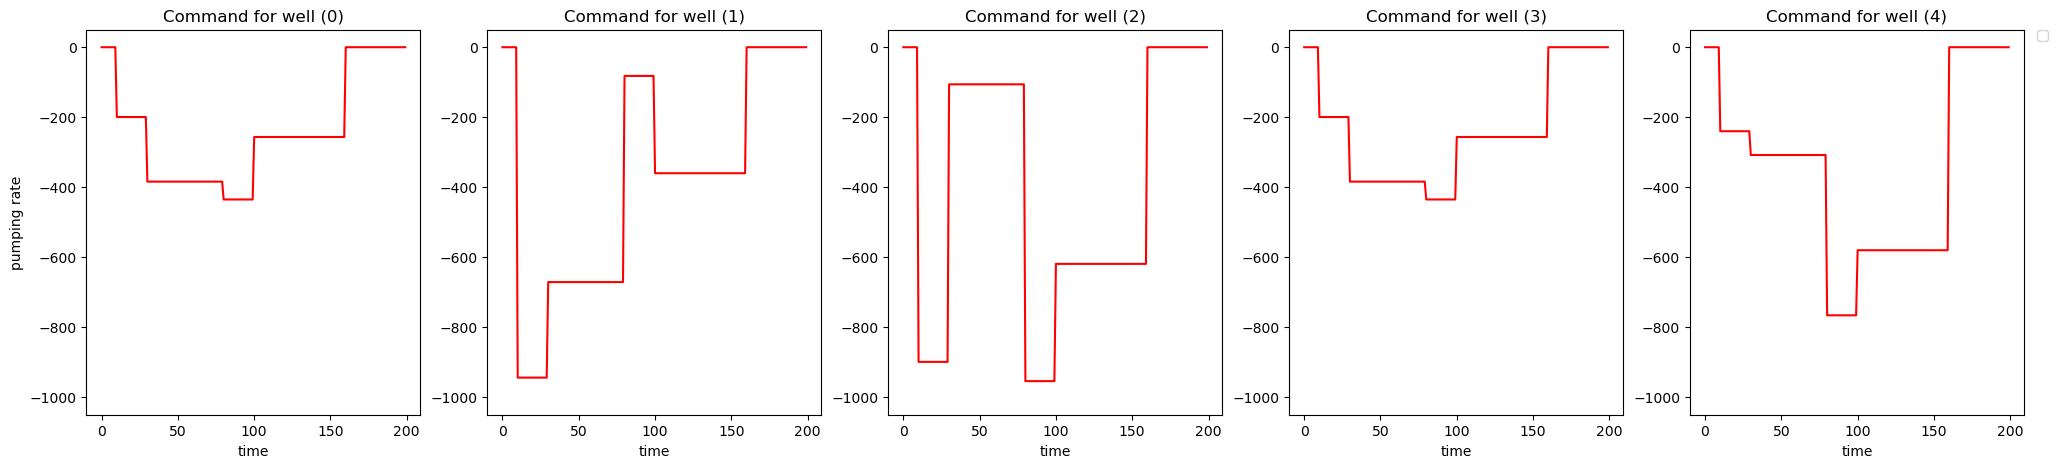

In [45]:
# Display Pumping
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(train_pumping[:, ii], "r-")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

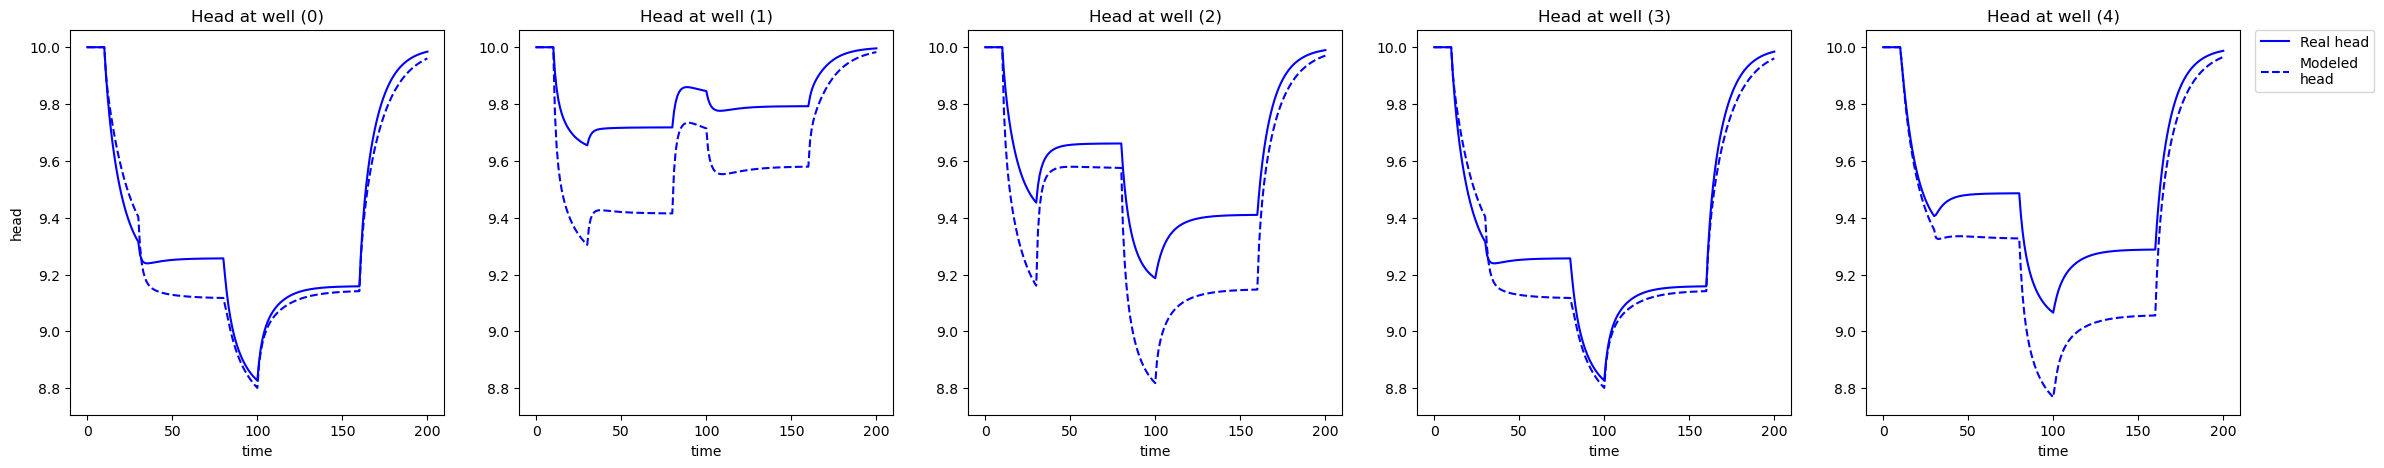

In [60]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(train_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(model_heads[:, well_pos[ii]], "b--", label="Modeled\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#### Compare with the first head predicted by the model in CL

In [61]:
model_heads_CL = np.zeros((train_input.shape[0]+1, model.nx))
model_heads_CL[0,:] = train_heads[0,:]
for k in trange(train_input.shape[0]):
    model_heads_CL[k+1,:] = (model.A @ train_heads[[k],:].T + B @ train_input[[k], :].T + model.C).flatten()

100%|██████████| 200/200 [00:00<00:00, 20210.59it/s]


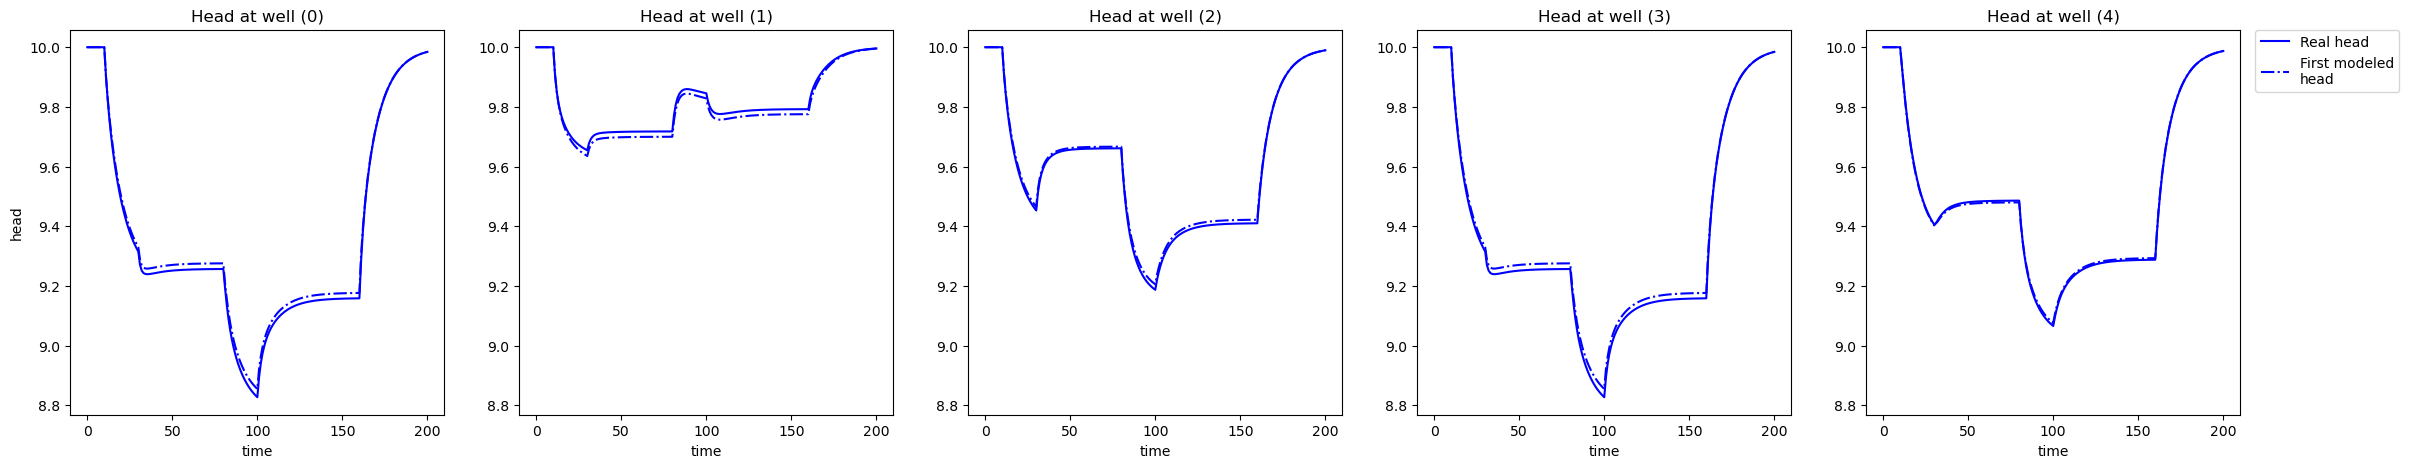

In [62]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(train_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(model_heads_CL[:, well_pos[ii]], "b-.", label="First modeled\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Fit dynamic matrices

We have $x_{t+1} = \begin{bmatrix} A & B & C \end{bmatrix} \begin{bmatrix} x_t \\ u_t \\ 1 \end{bmatrix}$

So : $\begin{bmatrix} x_t^T & u_t^T & 1 \end{bmatrix} \begin{bmatrix} A^T \\ B^T \\ C^T \end{bmatrix} = x_{t+1}^T$

And: $\begin{bmatrix} x_0^T & u_0^T & 1 \\ x_1^T & u_1^T & 1 \\ & \vdots & \\ x_{T-1}^T & u_{T-1}^T & 1 \end{bmatrix} \begin{bmatrix} A^T \\ B^T \\ C^T \end{bmatrix} =  \begin{bmatrix} x_1^T \\ x_2^T \\ \vdots \\ x_{T}^T \end{bmatrix}$

In [63]:
# We search the least square solution of the problem Ax=b
A_lstq = np.hstack((train_heads[:-1,:], train_input, np.ones((train_input.shape[0],1))))
b_lstq = train_heads[1:,:]
x_lstq, res_lstq, rank, s = np.linalg.lstsq(A_lstq,b_lstq)
# Decompose to find dynamic matrices
A_fit = x_lstq[:model.nx,:].T
B_fit = x_lstq[model.nx:-1, :].T
C_fit = x_lstq[-1:, :].T

#### Compare predicted heads

##### Training data

In [64]:
fit_heads = np.zeros((train_input.shape[0]+1, model.nx))
fit_heads[0,:] = train_heads[0,:]
fit_heads_CL = np.zeros((train_input.shape[0]+1, model.nx))
fit_heads_CL[0,:] = train_heads[0,:]
for k in trange(train_input.shape[0]):
    fit_heads[k+1,:] = (A_fit @ fit_heads[[k],:].T + B_fit @ train_input[[k], :].T + C_fit).flatten()
    fit_heads_CL[k+1,:] = (A_fit @ train_heads[[k],:].T + B_fit @ train_input[[k], :].T + C_fit).flatten()

100%|██████████| 200/200 [00:00<00:00, 21734.40it/s]


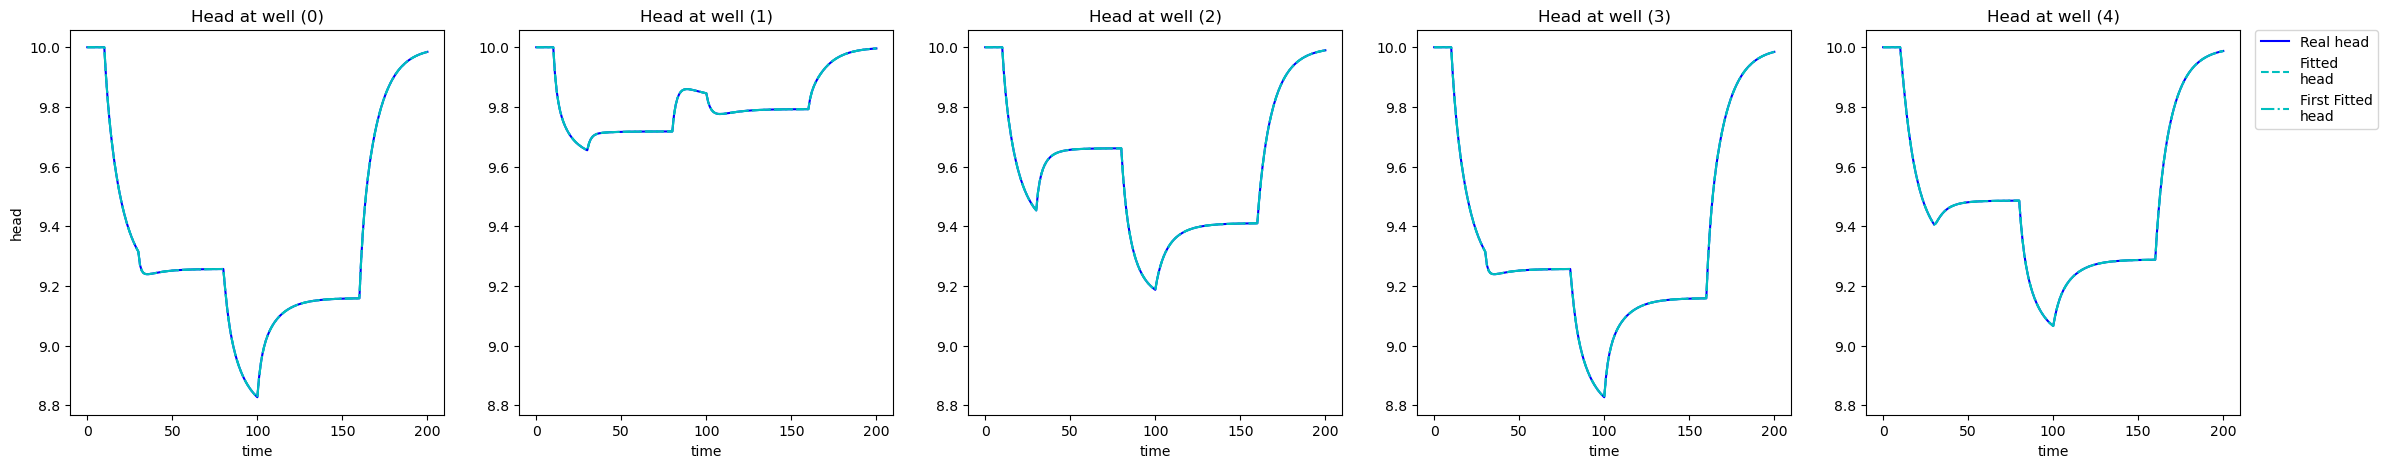

In [65]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(train_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(fit_heads[:, well_pos[ii]], "c--", label="Fitted\nhead")
    ax_h.plot(fit_heads_CL[:, well_pos[ii]], "c-.", label="First Fitted\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

##### Testing data

In [66]:
# Define testing inputs
test_input = np.vstack([np.zeros((10, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((20, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((50, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((20, 4)),
                         np.random.randint(-1000,0, (1,4))*np.ones((60, 4)),
                         np.zeros((40, 4))])

In [67]:
# Reinitialize initial state
system.state = system.initial_state.copy()
# Compute testing heads
test_heads = np.zeros((test_input.shape[0]+1, model.nx))
test_heads[0,:] = model.translate_state(system.get_state()[0,:,:]).flatten()
test_pumping = np.zeros((test_input.shape[0], len(system.well_pos)))
for k in trange(test_input.shape[0]):
    test_pumping[k, :] = model.translate_input(test_input[[k],:].T).flatten()
    system.apply_command(test_pumping[[k], :].T)
    test_heads[k+1,:] = model.translate_state(system.get_state()[0,:,:]).flatten()

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:20<00:00,  9.91it/s]


In [68]:
test_fit_heads = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads[0,:] = test_heads[0,:]
test_fit_heads_CL = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads_CL[0,:] = test_heads[0,:]
for k in trange(test_input.shape[0]):
    test_fit_heads[k+1,:] = (A_fit @ test_fit_heads[[k],:].T + B_fit @ test_input[[k], :].T + C_fit).flatten()
    test_fit_heads_CL[k+1,:] = (A_fit @ test_heads[[k],:].T + B_fit @ test_input[[k], :].T + C_fit).flatten()

100%|██████████| 200/200 [00:00<00:00, 10674.16it/s]


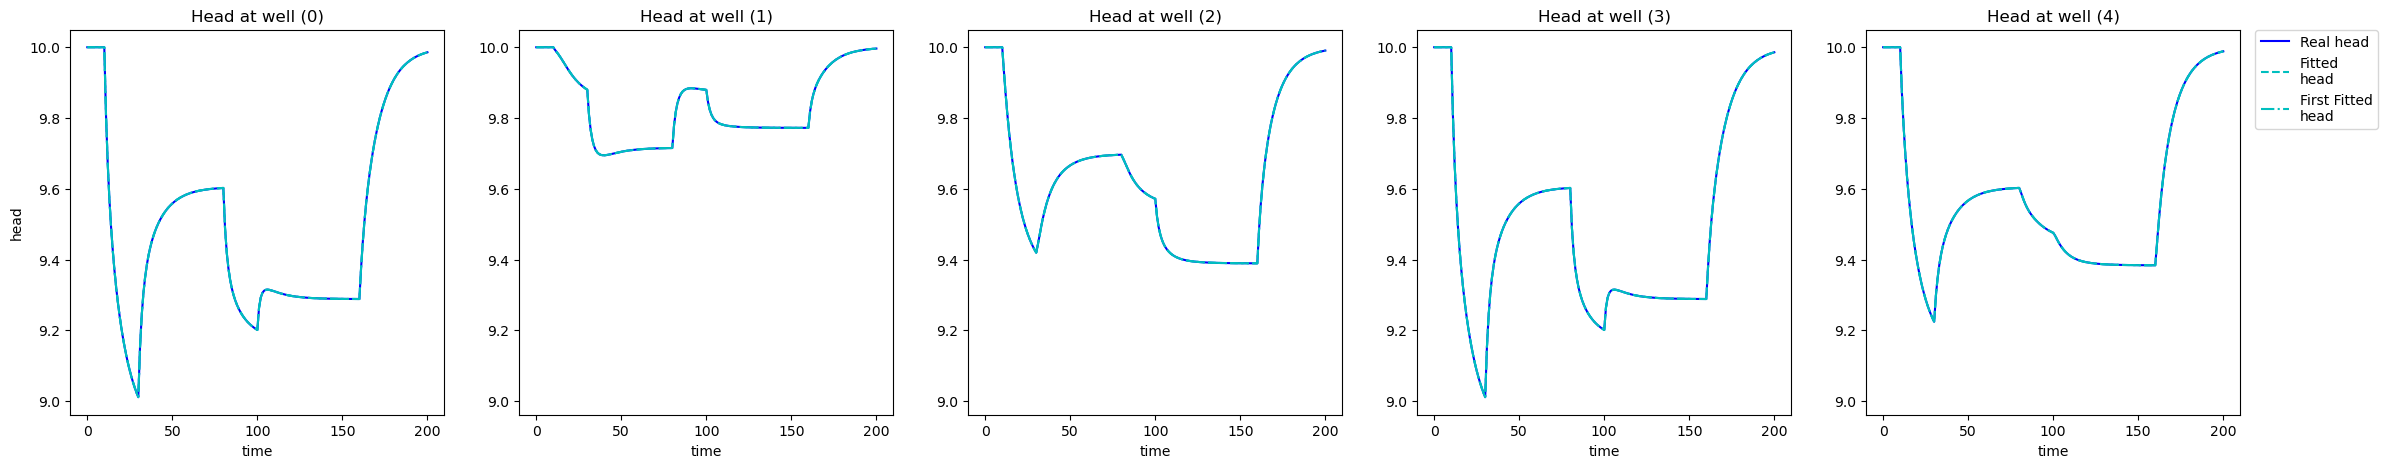

In [69]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(test_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(test_fit_heads[:, well_pos[ii]], "c--", label="Fitted\nhead")
    ax_h.plot(test_fit_heads_CL[:, well_pos[ii]], "c-.", label="First Fitted\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

TODO:
- compare matrices
- test controller with fitted matrices
- Later: observe if it is still as perfect with inhomogeneous aquifer parameters (K,S)

# Compare matrices

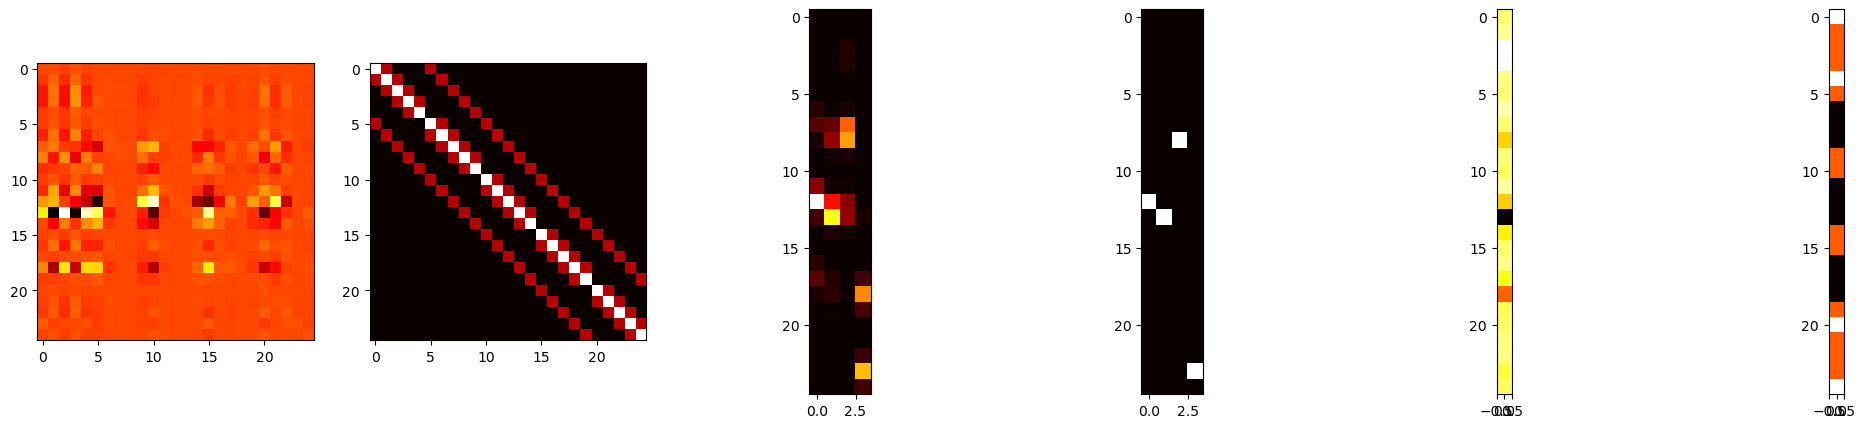

In [73]:
f, axarr = plt.subplots(1,6, figsize=(25,5))
axarr[0].imshow(A_fit, cmap='hot', interpolation='nearest')
axarr[1].imshow(model.A.toarray(), cmap='hot', interpolation='nearest')
axarr[2].imshow(B_fit, cmap='hot', interpolation='nearest')
axarr[3].imshow(B.toarray(), cmap='hot', interpolation='nearest')
axarr[4].imshow(C_fit, cmap='hot', interpolation='nearest')
axarr[5].imshow(model.C, cmap='hot', interpolation='nearest')

In [74]:
(A_fit.T == A_fit).all()

np.False_

A_fit is not symmetric. It should be: in the current setting, the impact of cell i to cell j is the same as the one from j to i.

In [75]:
x_lstq.shape[0]*x_lstq.shape[1], A_lstq.shape[0]

(750, 200)

We don't have enough equations to uniquely characterize the matrices (if we don't specify symmetry of A)

# Increase training data

In [76]:
# Define testing inputs
train_input_ext = np.vstack([np.zeros((20, 4)),
                         np.kron(np.random.randint(-1000,0, (200,4)), np.ones((5,1))),
                         np.zeros((40, 4))])
train_input_ext.shape

(1060, 4)

In [77]:
# Reinitialize initial state
system.state = system.initial_state.copy()
# Compute resulting heads
train_heads_ext = np.zeros((train_input_ext.shape[0]+1, model.nx))
train_heads_ext[0,:] = model.translate_state(system.get_state()[0,:,:]).flatten()
train_pumping_ext = np.zeros((train_input_ext.shape[0], len(system.well_pos)))
for k in trange(train_input_ext.shape[0]):
    train_pumping_ext[k, :] = model.translate_input(train_input_ext[[k],:].T).flatten()
    system.apply_command(train_pumping_ext[[k], :].T)
    train_heads_ext[k+1,:] = model.translate_state(system.get_state()[0,:,:]).flatten()

  0%|          | 1/1060 [00:00<02:01,  8.75it/s]

100%|██████████| 1060/1060 [01:42<00:00, 10.35it/s]


In [78]:
# We search the least square solution of the problem Ax=b
A_lstq_ext = np.hstack((train_heads_ext[:-1,:], train_input_ext, np.ones((train_input_ext.shape[0],1))))
b_lstq_ext = train_heads_ext[1:,:]
x_lstq_ext, res_lstq_ext, rank, s = np.linalg.lstsq(A_lstq_ext,b_lstq_ext)
# Decompose to find dynamic matrices
A_fit_ext = x_lstq_ext[:model.nx,:].T
B_fit_ext = x_lstq_ext[model.nx:-1, :].T
C_fit_ext = x_lstq_ext[-1:, :].T

Test data

In [79]:
test_fit_heads_ext = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads_ext[0,:] = test_heads[0,:]
test_fit_heads_CL_ext = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads_CL_ext[0,:] = test_heads[0,:]
for k in trange(test_input.shape[0]):
    test_fit_heads_ext[k+1,:] = (A_fit_ext @ test_fit_heads_ext[[k],:].T + B_fit_ext @ test_input[[k], :].T + C_fit_ext).flatten()
    test_fit_heads_CL_ext[k+1,:] = (A_fit_ext @ test_heads[[k],:].T + B_fit_ext @ test_input[[k], :].T + C_fit_ext).flatten()

100%|██████████| 200/200 [00:00<00:00, 15210.26it/s]


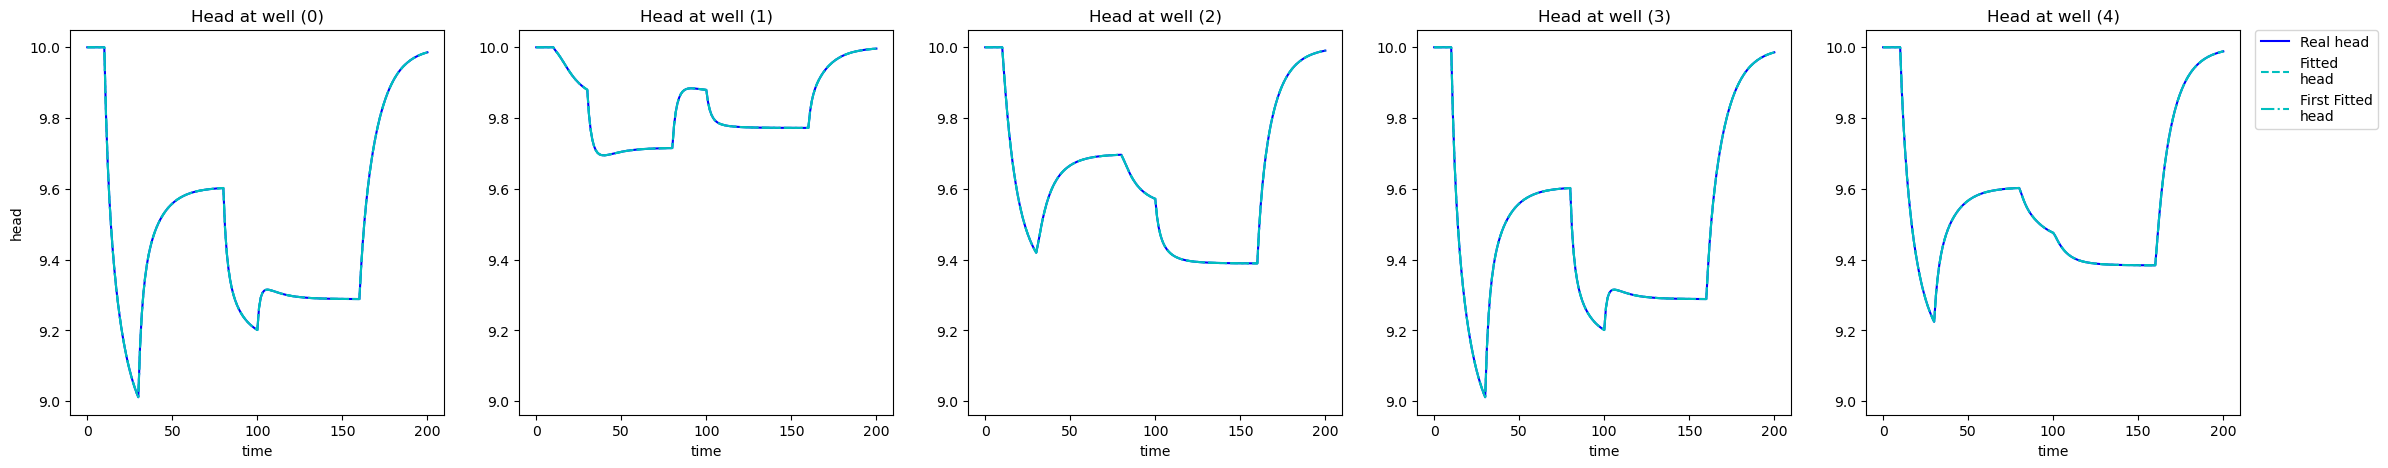

In [80]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(test_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(test_fit_heads_ext[:, well_pos[ii]], "c--", label="Fitted\nhead")
    ax_h.plot(test_fit_heads_CL_ext[:, well_pos[ii]], "c-.", label="First Fitted\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Compare matrices

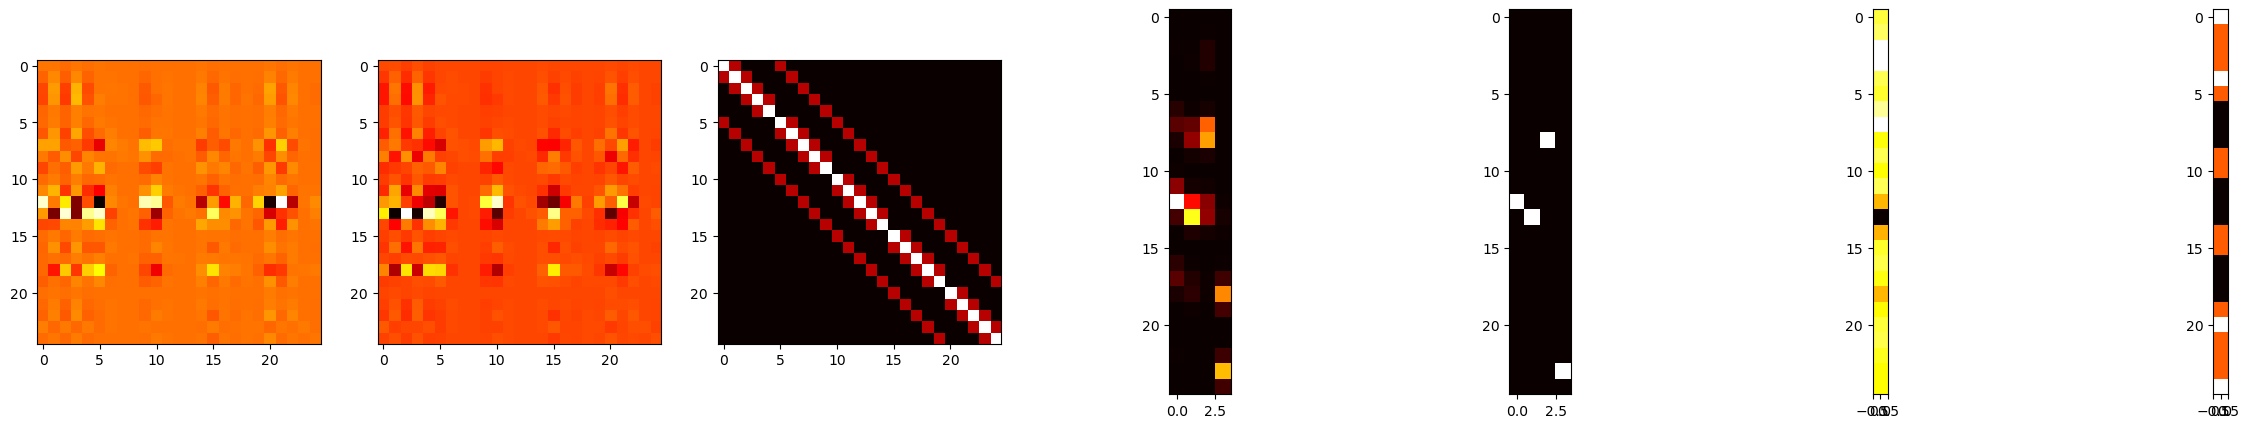

In [81]:
f, axarr = plt.subplots(1,7, figsize=(30,5))
axarr[0].imshow(A_fit_ext, cmap='hot', interpolation='nearest')
axarr[1].imshow(A_fit, cmap='hot', interpolation='nearest')
axarr[2].imshow(model.A.toarray(), cmap='hot', interpolation='nearest')
axarr[3].imshow(B_fit_ext, cmap='hot', interpolation='nearest')
axarr[4].imshow(B.toarray(), cmap='hot', interpolation='nearest')
axarr[5].imshow(C_fit_ext, cmap='hot', interpolation='nearest')
axarr[6].imshow(model.C, cmap='hot', interpolation='nearest')

In [82]:
x_lstq_ext.shape[0]*x_lstq_ext.shape[1], A_lstq_ext.shape[0]

(750, 1060)

Doest not change much

In [83]:
A_fit_ext.min()

np.float64(-22.642834385190568)

Should also not have negative values.

# Impose symmetry

In [84]:
import gurobipy as gp

In [85]:
select_A = np.vstack((np.eye(model.nx), np.zeros((x_lstq.shape[0]-model.nx, x_lstq.shape[1]))))

In [86]:
A_lstq_ext.shape, x_lstq.shape, b_lstq_ext.shape

((1060, 30), (30, 25), (1060, 25))

In [87]:
m = gp.Model("matrix1")

x_gp = m.addMVar(shape=x_lstq.shape, lb=0., ub=np.inf, vtype=gp.GRB.CONTINUOUS, name="x_gp")

m.addConstr(x_gp.T @ select_A == select_A.T @ x_gp, name="sym")

m.setObjective( np.ones((1,1060)) @ (((A_lstq_ext @ x_gp - b_lstq_ext)**2) @ np.ones((25,1))) , gp.GRB.MINIMIZE)

In [88]:
m.optimize()

Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (mac64[x86] - Darwin 24.5.0 24F74)

CPU model: Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 625 rows, 750 columns and 1200 nonzeros
Model fingerprint: 0x035df2e6
Model has 11625 quadratic objective terms
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e+04, 1e+07]
  QObjective range [2e+03, 1e+09]
  Bounds range     [0e+00, 0e+00]
  RHS range        [0e+00, 0e+00]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 325 rows and 0 columns
Presolve time: 0.02s
Presolved: 300 rows, 750 columns, 600 nonzeros
Presolved model has 11625 quadratic objective terms
Ordering time: 0.01s

Barrier statistics:
 Free vars  : 550
 AA' NZ     : 1.528e+04
 Factor NZ  : 6.222e+04 (roughly 1 MB of memory)
 Factor Ops : 7.403e+06 (less than 1 second per iterati

In [89]:
# Decompose to find dynamic matrices
A_fit_sym = x_gp.X[:model.nx,:].T
B_fit_sym = x_gp.X[model.nx:-1, :].T
C_fit_sym = x_gp.X[-1:, :].T

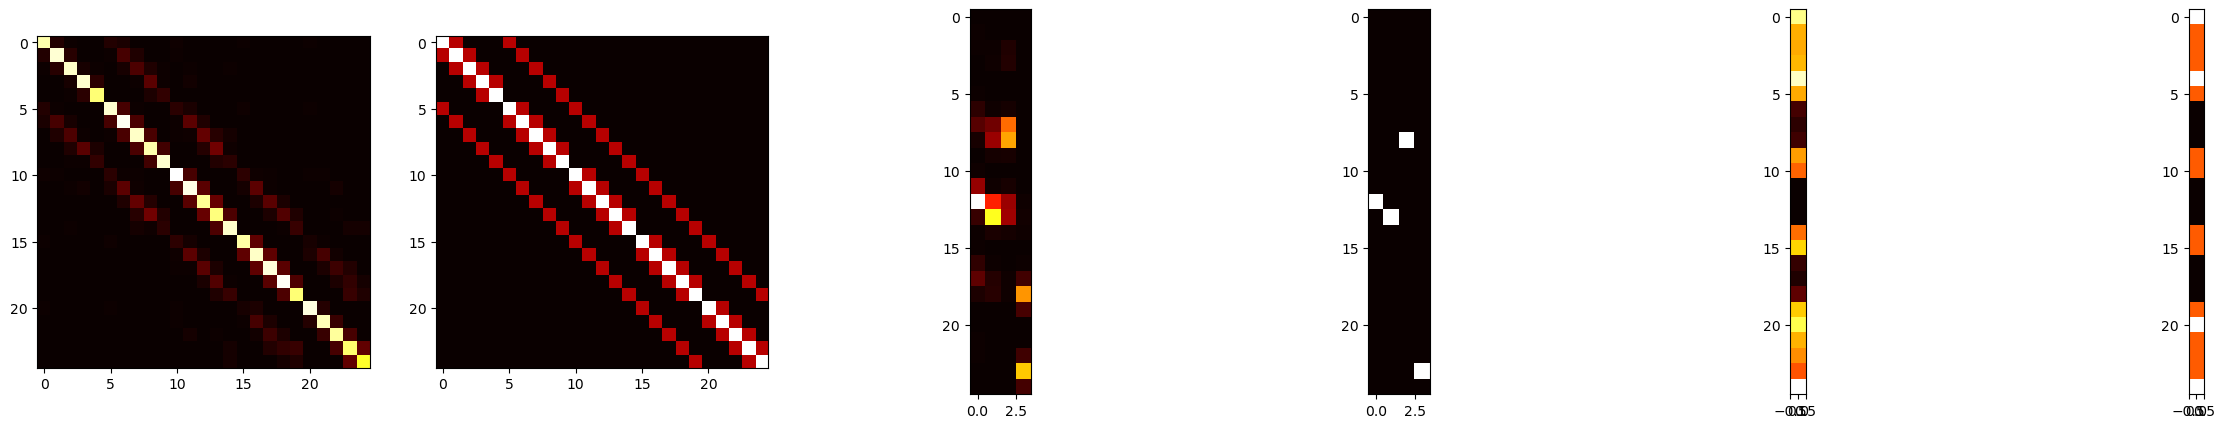

In [90]:
f, axarr = plt.subplots(1,6, figsize=(30,5))
axarr[0].imshow(A_fit_sym, cmap='hot', interpolation='nearest')
axarr[1].imshow(model.A.toarray(), cmap='hot', interpolation='nearest')
axarr[2].imshow(B_fit_sym, cmap='hot', interpolation='nearest')
axarr[3].imshow(B.toarray(), cmap='hot', interpolation='nearest')
axarr[4].imshow(C_fit_sym, cmap='hot', interpolation='nearest')
axarr[5].imshow(model.C, cmap='hot', interpolation='nearest')

In [91]:
test_fit_heads_sym = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads_sym[0,:] = test_heads[0,:]
test_fit_heads_CL_sym = np.zeros((test_input.shape[0]+1, model.nx))
test_fit_heads_CL_sym[0,:] = test_heads[0,:]
for k in trange(test_input.shape[0]):
    test_fit_heads_sym[k+1,:] = (A_fit_sym @ test_fit_heads_sym[[k],:].T + B_fit_sym @ test_input[[k], :].T + C_fit_sym).flatten()
    test_fit_heads_CL_sym[k+1,:] = (A_fit_sym @ test_heads[[k],:].T + B_fit_sym @ test_input[[k], :].T + C_fit_sym).flatten()

100%|██████████| 200/200 [00:00<00:00, 11545.33it/s]


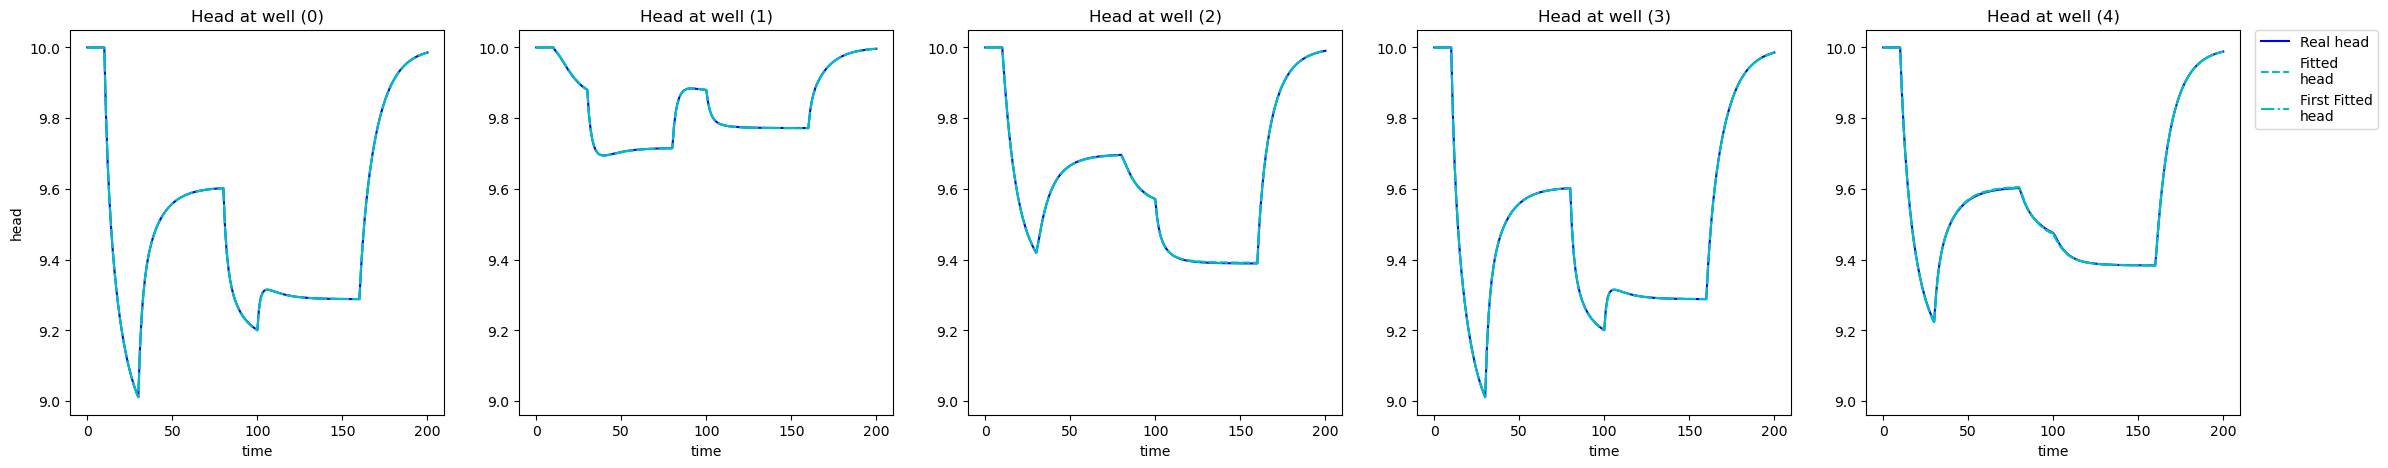

In [92]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(test_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(test_fit_heads_sym[:, well_pos[ii]], "c--", label="Fitted\nhead")
    ax_h.plot(test_fit_heads_CL_sym[:, well_pos[ii]], "c-.", label="First Fitted\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

##### Compare with accuracy of model

In [93]:
model_heads_test = np.zeros((train_input.shape[0]+1, model.nx))
model_heads_test[0,:] = train_heads[0,:]
model_heads_test_CL = model_heads_test.copy()
for k in trange(train_input.shape[0]):
    model_heads_test[k+1,:] = (model.A @ model_heads_test[[k],:].T + B @ test_input[[k], :].T + model.C).flatten()
    model_heads_test_CL[k+1,:] = (model.A @ test_heads[[k],:].T + B @ test_input[[k], :].T + model.C).flatten()

100%|██████████| 200/200 [00:00<00:00, 3866.82it/s]


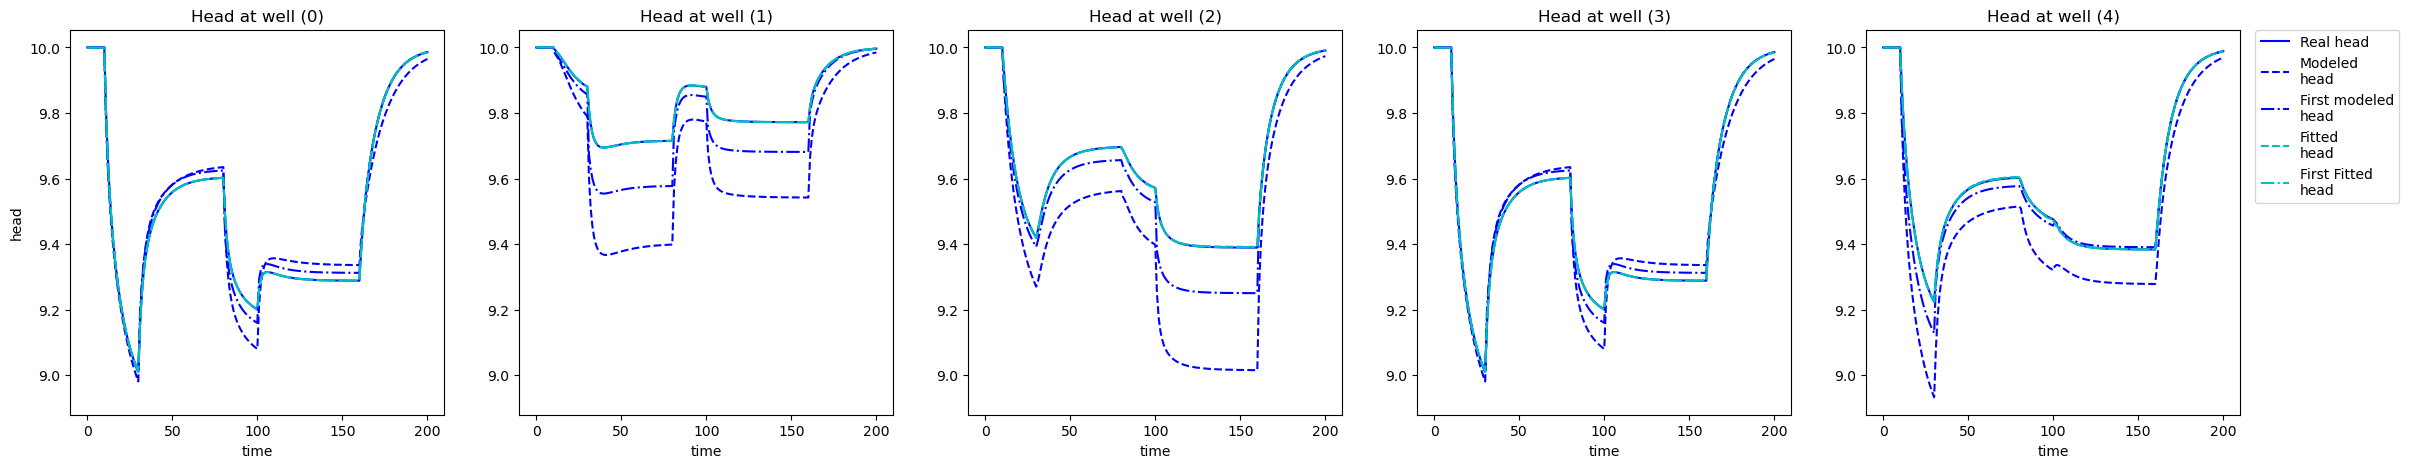

In [94]:
# Compare heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(test_heads[:, well_pos[ii]], "b-", label="Real head")
    ax_h.plot(model_heads_test[:, well_pos[ii]], "b--", label="Modeled\nhead")
    ax_h.plot(model_heads_test_CL[:, well_pos[ii]], "b-.", label="First modeled\nhead")
    ax_h.plot(test_fit_heads_sym[:, well_pos[ii]], "c--", label="Fitted\nhead")
    ax_h.plot(test_fit_heads_CL_sym[:, well_pos[ii]], "c-.", label="First Fitted\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

Very good. But we wont always be able to impose symmetry.

# Impose positivity

In [95]:
from scipy.optimize import least_squares

In [96]:
m = gp.Model("matrix1")
x_gp_pos = m.addMVar(shape=x_lstq.shape, lb=0., ub=np.inf, vtype=gp.GRB.CONTINUOUS, name="x_gp")
m.addConstr(x_gp_pos >= 0, name="pos")
m.setObjective( np.ones((1,1060)) @ (((A_lstq_ext @ x_gp_pos - b_lstq_ext)**2) @ np.ones((25,1))) , gp.GRB.MINIMIZE)
m.optimize()
# Decompose to find dynamic matrices
A_fit_pos = x_gp_pos.X[:model.nx,:].T
B_fit_pos = x_gp_pos.X[model.nx:-1, :].T
C_fit_pos = x_gp_pos.X[-1:, :].T

Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (mac64[x86] - Darwin 24.5.0 24F74)

CPU model: Intel(R) Core(TM) i5-1038NG7 CPU @ 2.00GHz
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 750 rows, 750 columns and 750 nonzeros
Model fingerprint: 0xfd0d5bfd
Model has 11625 quadratic objective terms
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e+04, 1e+07]
  QObjective range [2e+03, 1e+09]
  Bounds range     [0e+00, 0e+00]
  RHS range        [0e+00, 0e+00]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 750 rows and 0 columns
Presolve time: 0.01s
Presolved: 0 rows, 750 columns, 0 nonzeros
Presolved model has 11625 quadratic objective terms
Ordering time: 0.00s

Barrier statistics:
 Free vars  : 550
 AA' NZ     : 5.775e+03
 Factor NZ  : 6.325e+03 (roughly 1 MB of memory)
 Factor Ops : 9.488e+04 (less than 1 second per iteration)
 

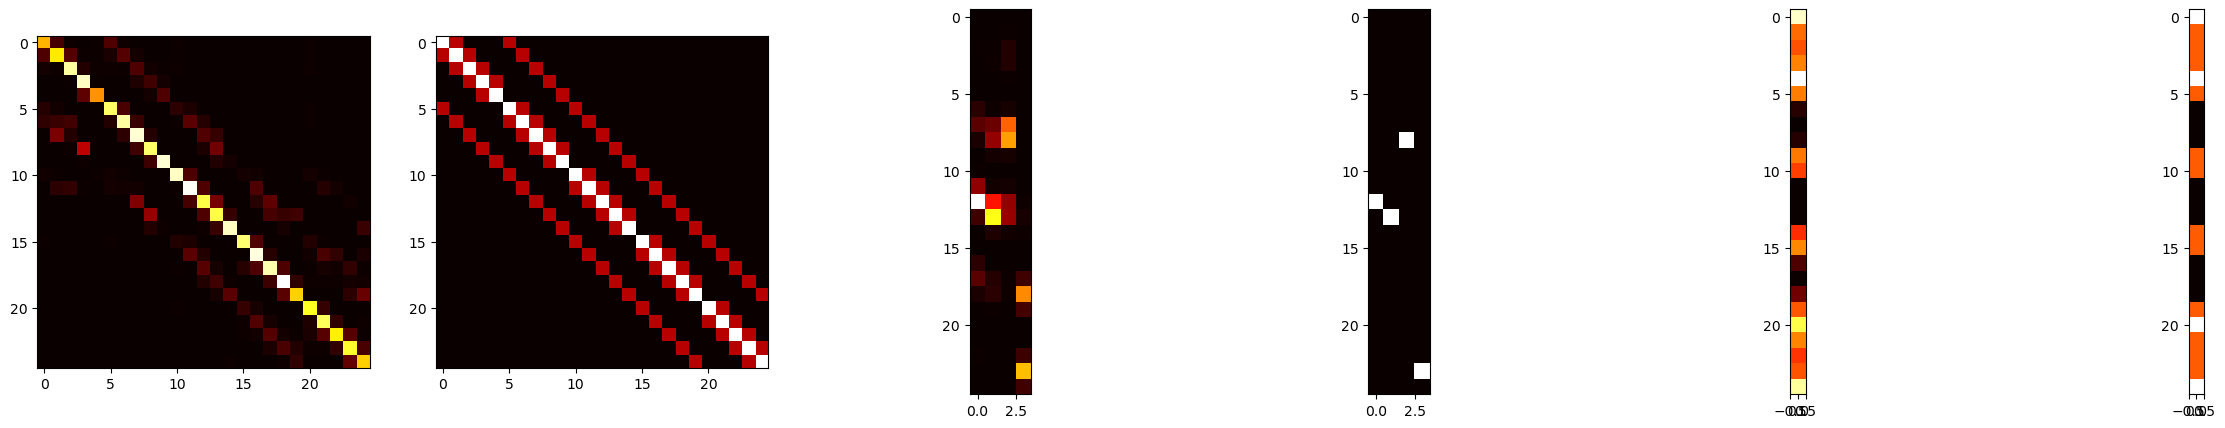

In [97]:
f, axarr = plt.subplots(1,6, figsize=(30,5))
axarr[0].imshow(A_fit_pos, cmap='hot', interpolation='nearest')
axarr[1].imshow(model.A.toarray(), cmap='hot', interpolation='nearest')
axarr[2].imshow(B_fit_pos, cmap='hot', interpolation='nearest')
axarr[3].imshow(B.toarray(), cmap='hot', interpolation='nearest')
axarr[4].imshow(C_fit_pos, cmap='hot', interpolation='nearest')
axarr[5].imshow(model.C, cmap='hot', interpolation='nearest')

Still not perfectly symmetric but better.

# Analysis of the fitted symmetrical matrix

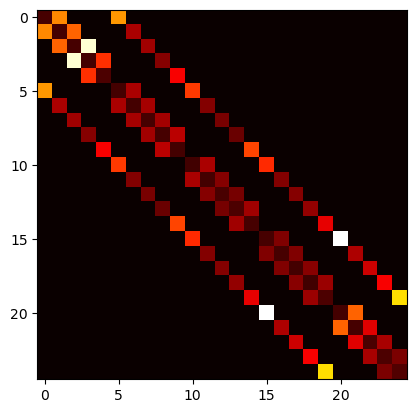

In [98]:
plt.imshow(model.A.toarray()/A_fit_sym, cmap='hot', interpolation='nearest')

(array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.27500000e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.27500000e-01, 4.90000000e-01, 1.27500000e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.27500000e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [2.68388853e-05, 4.08062418e-05, 4.21471715e-05, 2.93023602e-05, 2.88888142e-05, 4.53261768e-05, 2.13995947e-02, 8.78473116e-02, 2.56937668e-02, 4.70418832e-05, 5.32979949e-05, 7.83946258e-02, 5.83171295e-01, 8.95902821e-02, 4.98034876e-05, 4.98037078e-05, 1.81513121e-02, 7.75841116e-02, 1.74804838e-02, 3.58248202e-05, 2.64289911e-05, 4.16663215e-05, 4.33979140e-05, 4.65716151e-05, 2.75998976e-05]]),
 <matplotlib.image.AxesImage at 0x1acc58f50>)

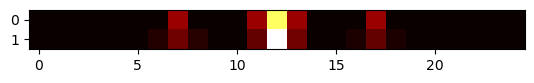

In [99]:
np.vstack((model.A.toarray()[12,:], A_fit_sym[12,:])), plt.imshow(np.vstack((model.A.toarray()[12,:], A_fit_sym[12,:])), cmap='hot', interpolation='nearest')

The impact of each cell only seems to be more spread out

In [100]:
A_fit_sym.sum(axis=1)

array([0.69132324, 0.77964726, 0.78333267, 0.77643447, 0.67087483, 0.78334913, 0.9695848 , 0.98096455, 0.9713451 , 0.78904259, 0.82008587, 0.99960487, 0.99994753, 0.99981737, 0.81385121, 0.75949238, 0.977033  , 0.9880882 , 0.95482772, 0.76557263, 0.71185658, 0.77879731, 0.79790428, 0.82835884, 0.64916151])

Let's try refine A

In [101]:
from Components.utils.mat_utils import matrix_poly_sum

In [102]:
r = 2
new_A_base = model.A.toarray()/r + (1-1/r)*np.eye(model.A.shape[0])
poly_A = sp.csr_array(matrix_poly_sum(new_A_base, r-1))
new_B_base = [B_v/r for B_v in model.B_v]
new_C_base = model.C/r
A_refined = sp.csr_array(np.linalg.matrix_power(new_A_base, r))
B_v_refined = [poly_A @ B_v for B_v in new_B_base]
C_refined = poly_A @ new_C_base

(array([[0.00000000e+00, 0.00000000e+00, 4.06406250e-03, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 8.12812500e-03, 9.49875000e-02, 8.12812500e-03, 0.00000000e+00, 4.06406250e-03, 9.49875000e-02, 5.71281250e-01, 9.49875000e-02, 4.06406250e-03, 0.00000000e+00, 8.12812500e-03, 9.49875000e-02, 8.12812500e-03, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 4.06406250e-03, 0.00000000e+00, 0.00000000e+00],
        [2.68388853e-05, 4.08062418e-05, 4.21471715e-05, 2.93023602e-05, 2.88888142e-05, 4.53261768e-05, 2.13995947e-02, 8.78473116e-02, 2.56937668e-02, 4.70418832e-05, 5.32979949e-05, 7.83946258e-02, 5.83171295e-01, 8.95902821e-02, 4.98034876e-05, 4.98037078e-05, 1.81513121e-02, 7.75841116e-02, 1.74804838e-02, 3.58248202e-05, 2.64289911e-05, 4.16663215e-05, 4.33979140e-05, 4.65716151e-05, 2.75998976e-05]]),
 <matplotlib.image.AxesImage at 0x1acc347d0>)

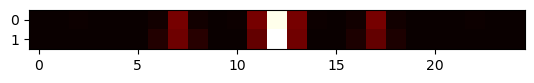

In [103]:
np.vstack((A_refined.toarray()[12,:], A_fit_sym[12,:])), plt.imshow(np.vstack((A_refined.toarray()[12,:], A_fit_sym[12,:])), cmap='hot', interpolation='nearest')

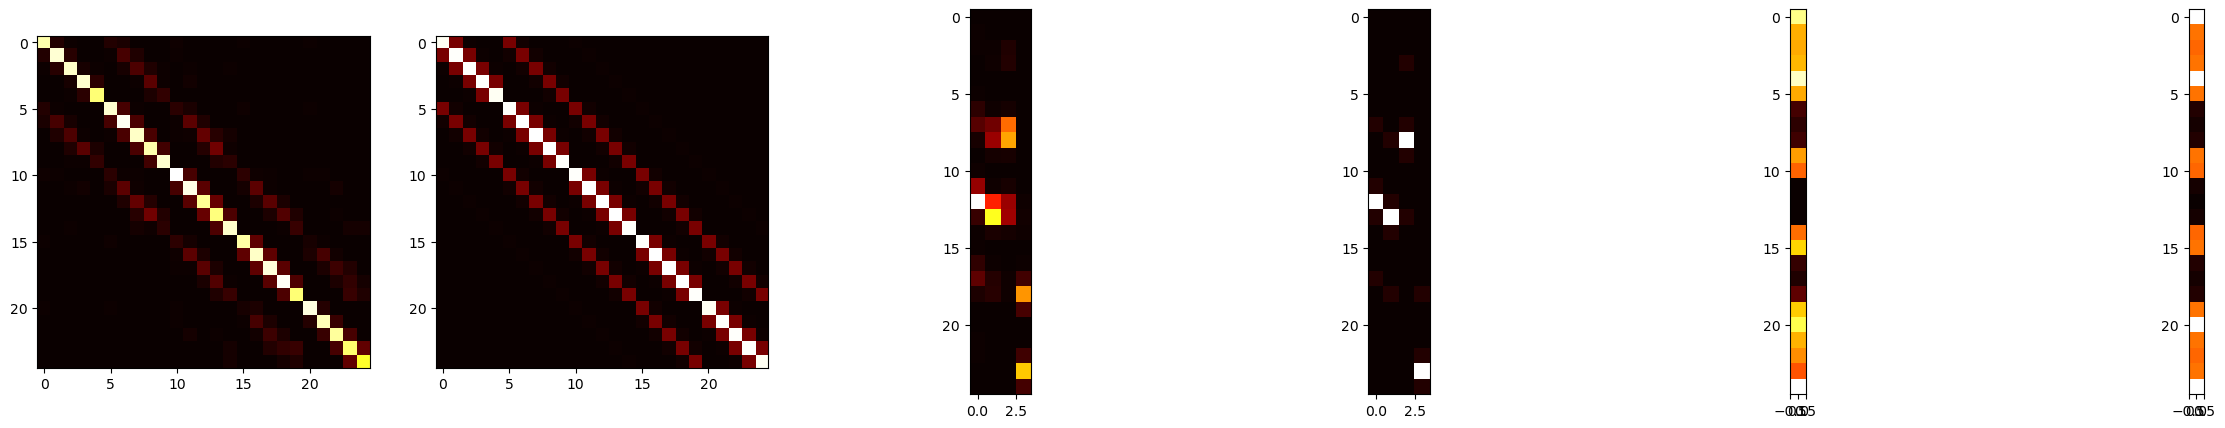

In [104]:
f, axarr = plt.subplots(1,6, figsize=(30,5))
axarr[0].imshow(A_fit_sym, cmap='hot', interpolation='nearest')
axarr[1].imshow(A_refined.toarray(), cmap='hot', interpolation='nearest')
axarr[2].imshow(B_fit_sym, cmap='hot', interpolation='nearest')
axarr[3].imshow(sp.hstack(B_v_refined).toarray(), cmap='hot', interpolation='nearest')
axarr[4].imshow(C_fit_sym, cmap='hot', interpolation='nearest')
axarr[5].imshow(C_refined, cmap='hot', interpolation='nearest')

In fact, main difference may be in B $\Rightarrow$ Surely because of the position of the wells in their cell

# Controller with fitted model

In [105]:
import copy

In [113]:
model_fitted = copy.deepcopy(model)
model_fitted.A = A_fit_sym
model_fitted.B_v = np.split(B_fit_sym, np.cumsum(model.nu_v)[:-1], axis=1)
model_fitted.C = C_fit_sym

In [107]:
# Initialize Controller
controller = LTI_LQRc_RHG_mixed_state(
    parameter_file,
    model_fitted.A, model_fitted.B_v, model_fitted.C,
    [A.toarray() for A in model_fitted.A_s_v], [B.toarray() for B in model_fitted.B_s_v], [C.toarray() for C in model_fitted.C_s_v],
    model_fitted.H_x, model_fitted.h_x, model_fitted.H_u_v, model_fitted.h_u_v,
    None, None,
    Q_v = [G.toarray() for G in model_fitted.Gamma_v_tilde], R_v = None, M_v = None, L_v = [Xi for Xi in model_fitted.Xi_v],
    solver='fbrs'
)

In [109]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model_fitted, controller, parameter_file)

Simulation progress: 100%|██████████| 200/200 [00:49<00:00,  4.02it/s]
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:113: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


array([[[9.999429 , 9.9988575, 9.998285 , ..., 9.997165 , 9.99811  , 9.999055 ],
        [9.9988575, 9.997715 , 9.996571 , ..., 9.994329 , 9.99622  , 9.99811  ],
        [9.998287 , 9.996573 , 9.994858 , ..., 9.991493 , 9.9943285, 9.997164 ],
        ...,
        [9.998427 , 9.996854 , 9.995278 , ..., 9.987227 , 9.991499 , 9.995753 ],
        [9.998951 , 9.997902 , 9.996851 , ..., 9.991471 , 9.994324 , 9.997165 ],
        [9.9994755, 9.998951 , 9.9984255, ..., 9.995731 , 9.997159 , 9.998581 ]]], shape=(1, 100, 100), dtype=float32)

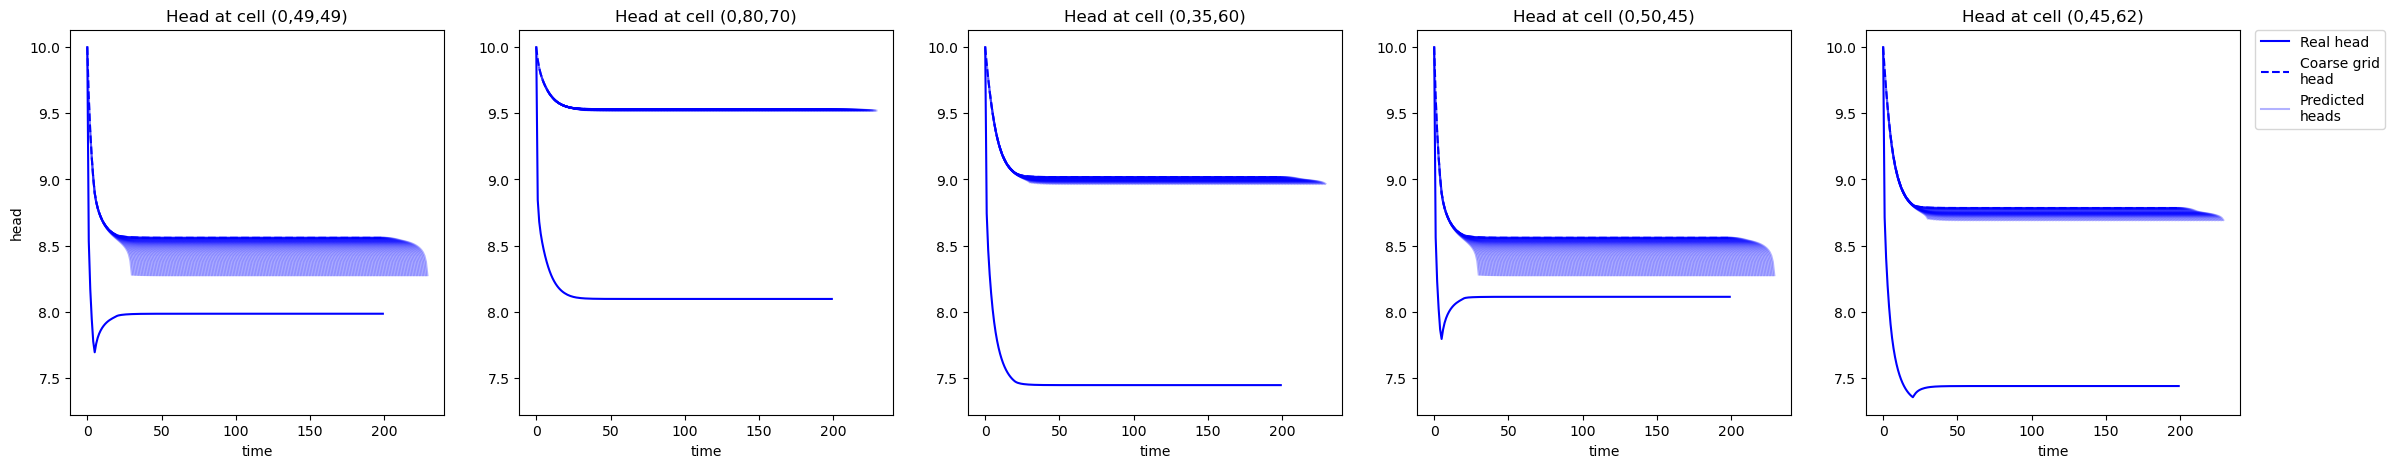

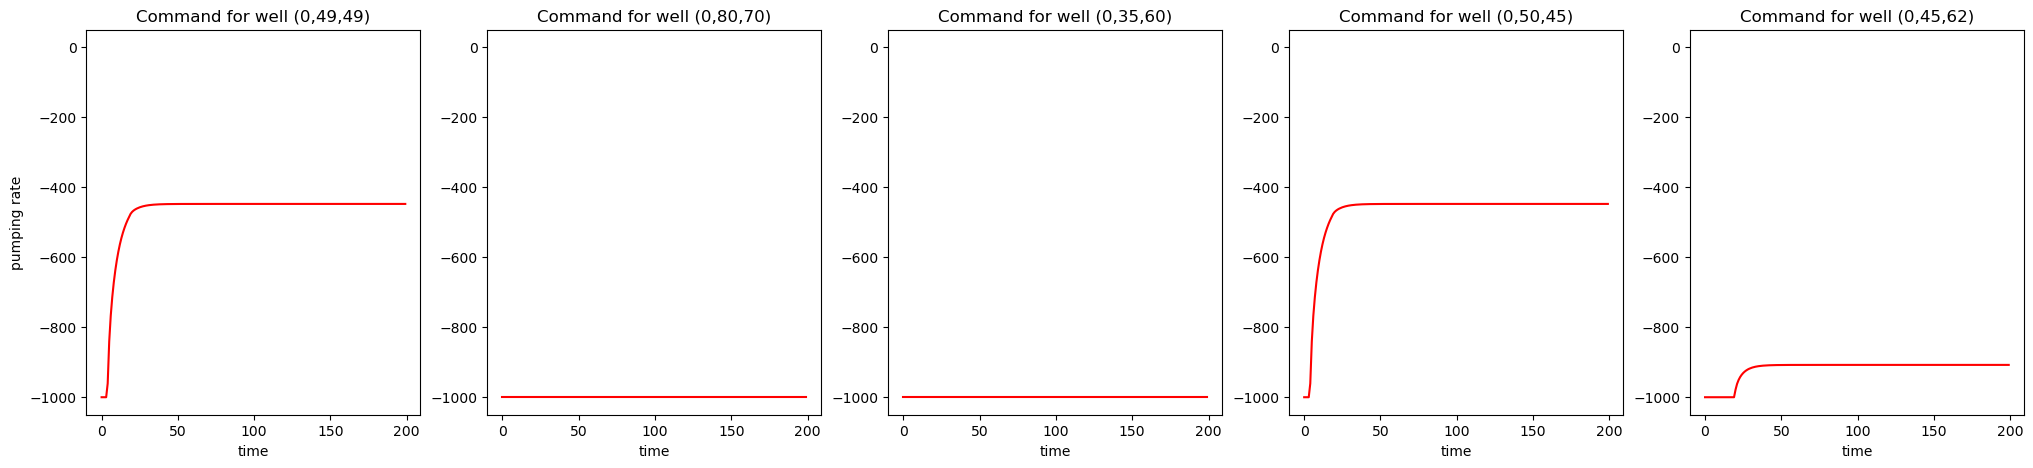

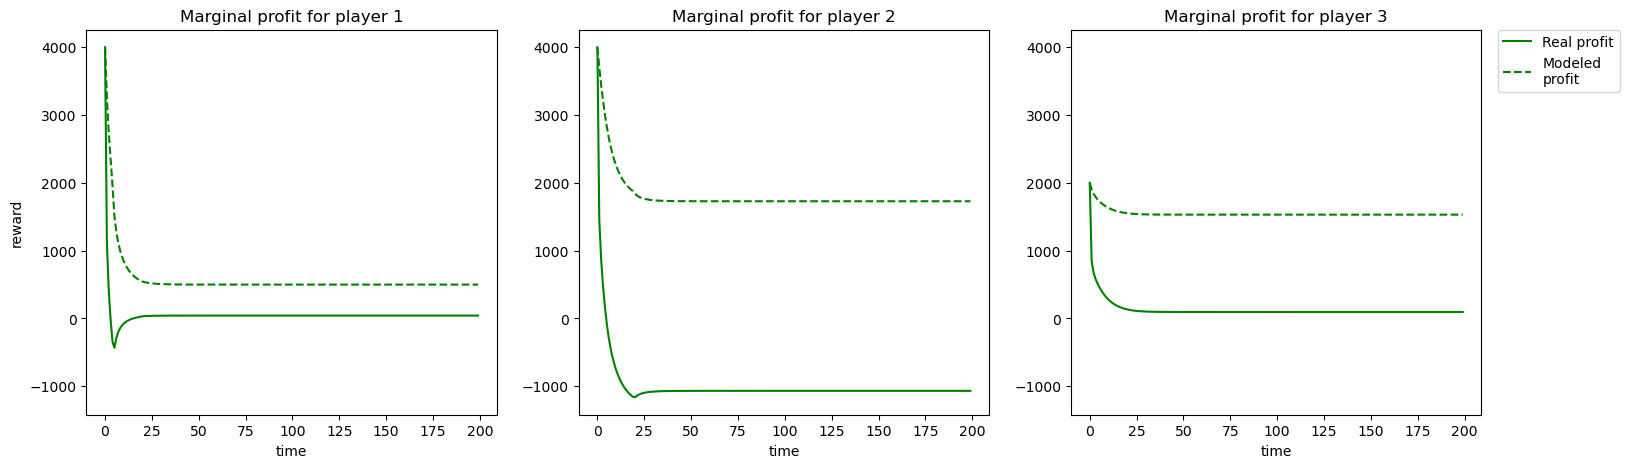

In [ ]:
# Run loop
#receding_horizon.run(time_period=200, display_results=True)

## Compare with steady-state equilibrium

This time the steady-state equilibrium because it is computed using the "perfect" dynamic matrices

In [124]:
nu = sum(model_fitted.nu_v)
# Cost matrices
M_v = [model_fitted.input_to_state_v[v] for v in range(model_fitted.n_agent)]
L_v = [-10*np.ones((1, model_fitted.nx)) @ model_fitted.input_to_state_v[v] + 2*np.ones(model_fitted.nu_v[v]) for v in range(model_fitted.n_agent)]
# Construct new Gamma and Xi matrices
I_A_inv = np.linalg.inv(np.eye(model_fitted.nx)-model_fitted.A)
B = np.hstack(model_fitted.B_v)
Gamma_v_tilde = [(I_A_inv@B).T @ M for M in M_v]
Xi_v_tilde = [(I_A_inv@model_fitted.C).T @ M + L  for M, L in zip(M_v,L_v)]
# Construct cost matrices
F = sp.block_diag([Gamma_v_tilde[v][sum(model_fitted.nu_v[:v]): sum(model_fitted.nu_v[:v+1])].T \
                   for v in range(model.n_agent)]).toarray()
F += np.vstack([Gamma.T for Gamma in Gamma_v_tilde])
f = np.vstack([Xi.T for Xi in Xi_v_tilde])
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model_fitted.H_u_v).toarray(),
    model_fitted.H_x @ I_A_inv @ B
])
h = np.vstack([
    sp.vstack(model_fitted.h_u_v).toarray(),
    model_fitted.h_x.toarray() - I_A_inv @ model_fitted.C
])
# Find equilibrium
u_s_0 = 1000*np.ones((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s = I_A_inv @ (B @ u_s + model_fitted.C)

In [125]:
u_s.T, x_s.T

(array([[ -897.50620533,  -882.34442596, -1000.        , -1000.        ]]),
 array([[9.93684979, 9.80666186, 9.68695748, 9.71640303, 9.89584801, 9.83289863, 9.45473496, 8.94503525, 9.02496213, 9.70776491, 9.79188557, 9.2834481 , 8.5693062 , 8.79773364, 9.63240956, 9.84267633, 9.50329978, 9.16110041, 9.09291051, 9.67421047, 9.94206182, 9.82485081, 9.68743234, 9.53189443, 9.8429736 ]]))

In [116]:
u_s_decomposed  = model_fitted.input_to_well.toarray() @ (u_s/np.count_nonzero(model_fitted.input_to_well.toarray(), axis=0)[:,np.newaxis])

In [117]:
data = np.load("run_data/run_20250521-174030/result_data.npz")

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this

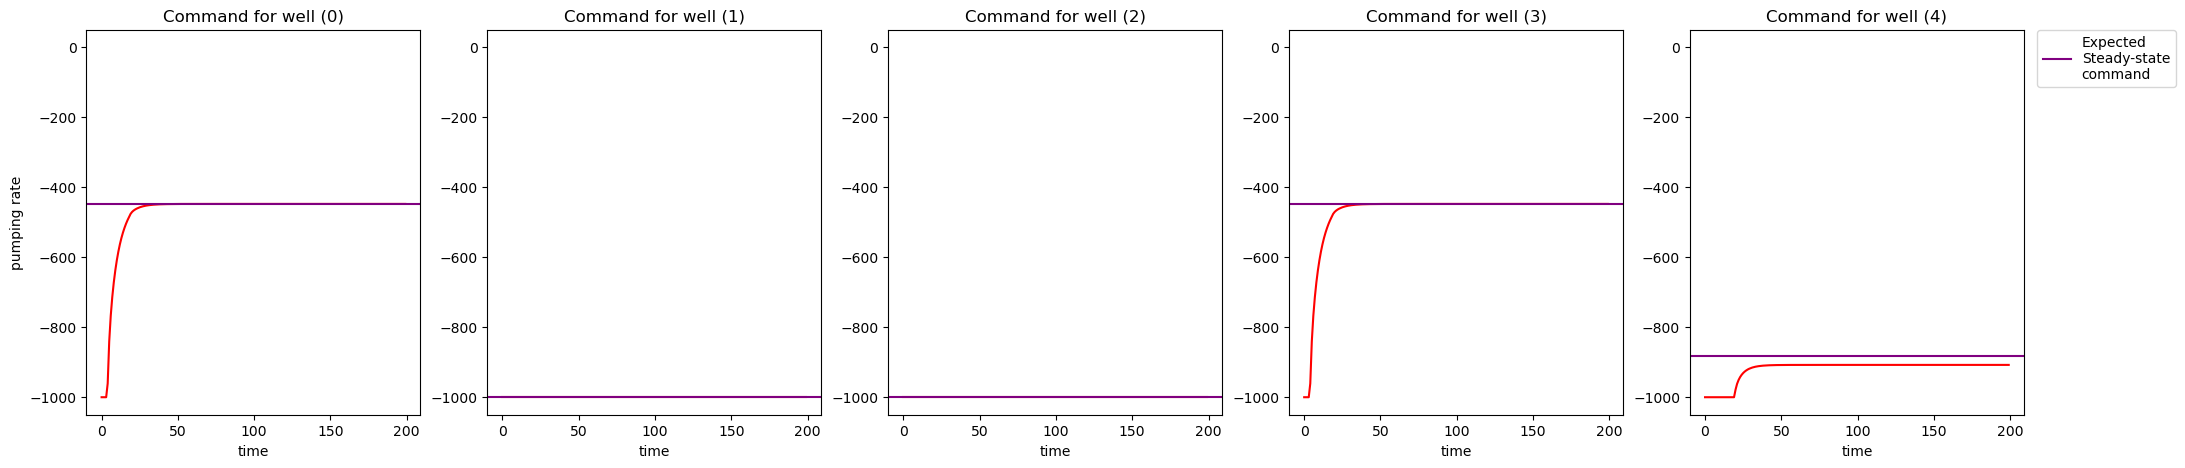

In [118]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data['q_rates'][ii, :], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

Whit these matrices, we are very close to the optimal. We could be even closer with a longer horizon since we face a Turnpike effect.

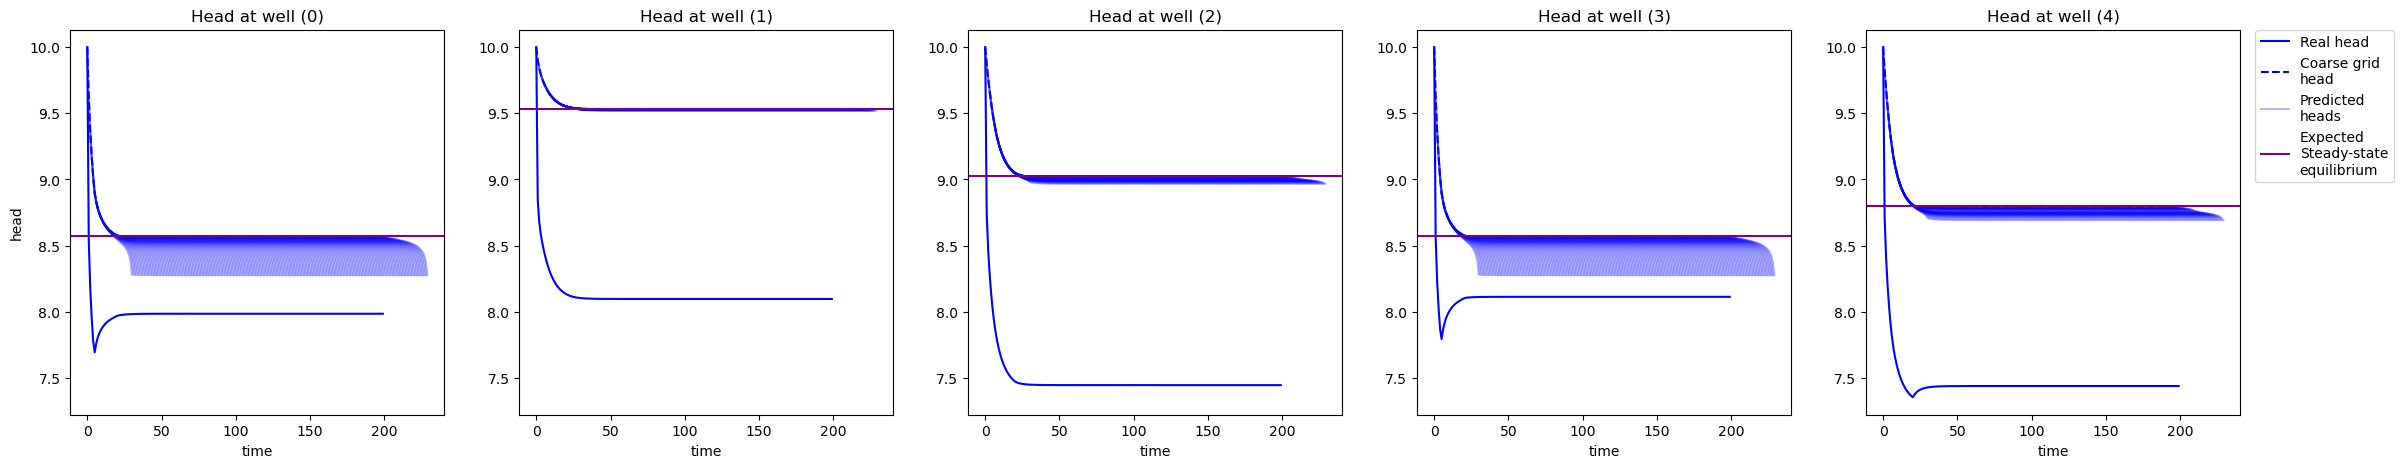

In [126]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,30, 31)
    for t0, h_pred in enumerate(np.rollaxis(data['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(model.select_wells(x_s)[ii,0], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

## Compare the imperfect model results to this equilibrium

In [ ]:
data = np.load("run_data/run_20250516-183948/result_data.npz")

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this

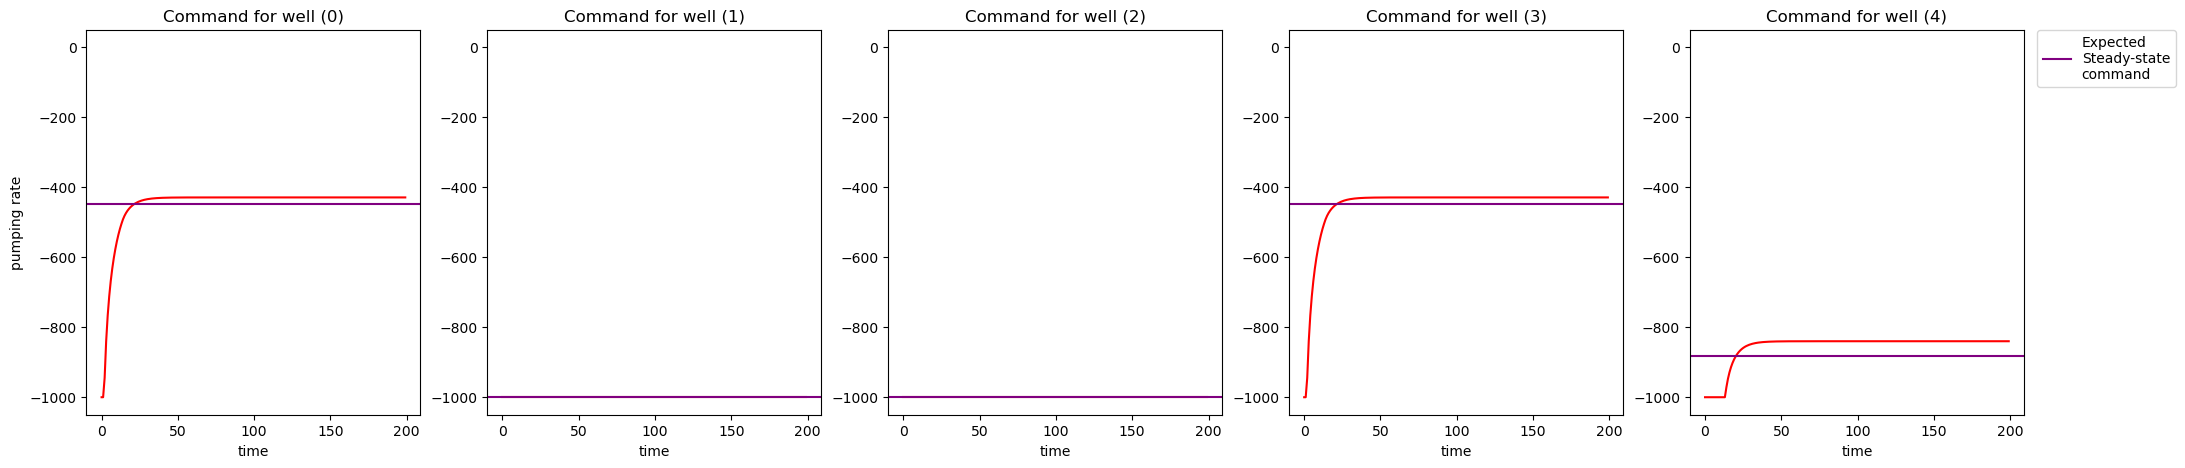

In [ ]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data['q_rates'][ii, :], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# First-step error

Compare first-step prediction error for different setups

In [ ]:
data = np.load("run_data/run_20250516-183948/result_data.npz")
data_10 = np.load("run_data/run_20250516-184453/result_data.npz")
data_20 = np.load("run_data/run_20250522-095718/result_data.npz")

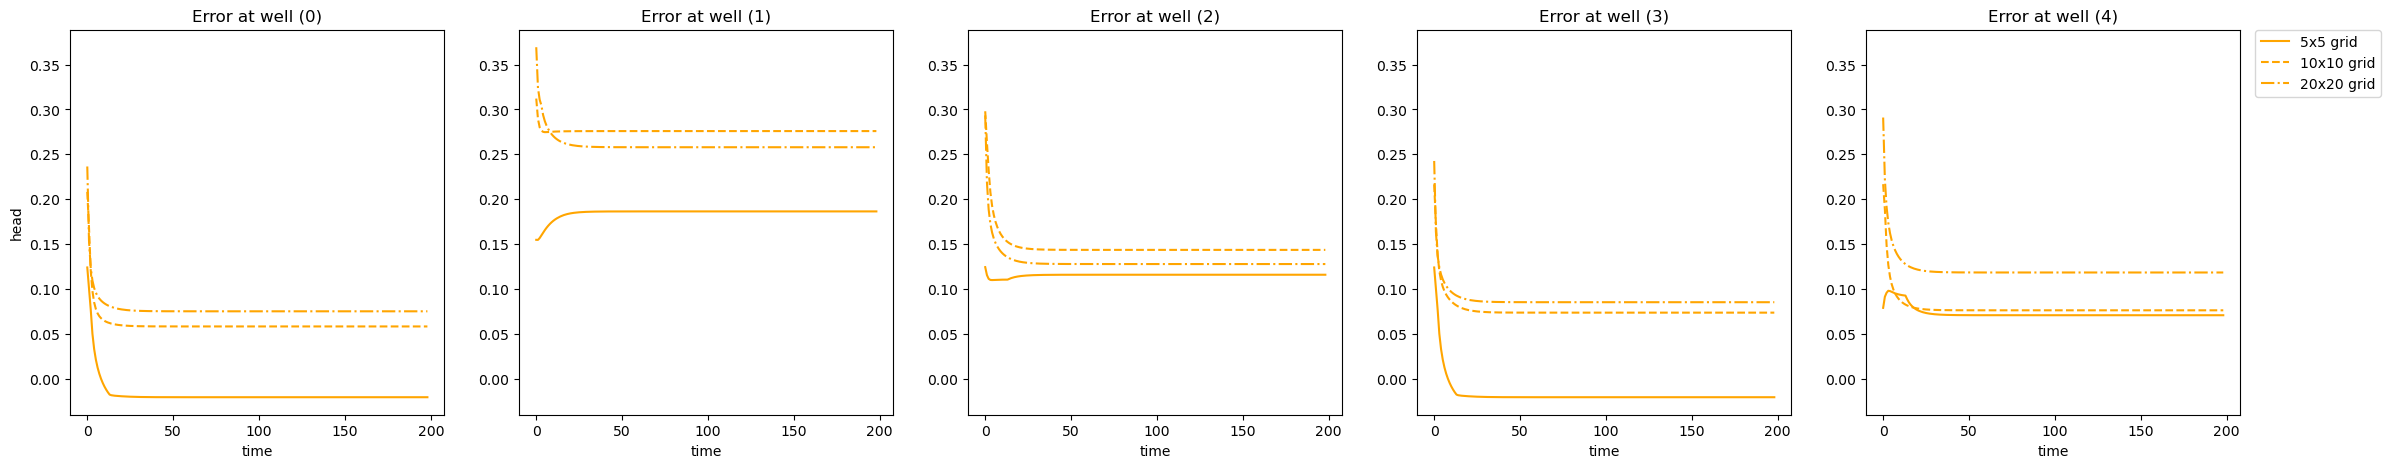

In [ ]:
# Display heads difference
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Error at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['avg_h_wells'][ii, 1:] - data['pred_avg_h_wells'][ii, 1, :-1], c="orange", label="5x5 grid")
    ax_h.plot(data_10['avg_h_wells'][ii, 1:] - data_10['pred_avg_h_wells'][ii, 1, :-1], c="orange", linestyle='--', label="10x10 grid")
    ax_h.plot(data_20['avg_h_wells'][ii, 1:] - data_20['pred_avg_h_wells'][ii, 1, :-1], c="orange", linestyle='-.', label="20x20 grid")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

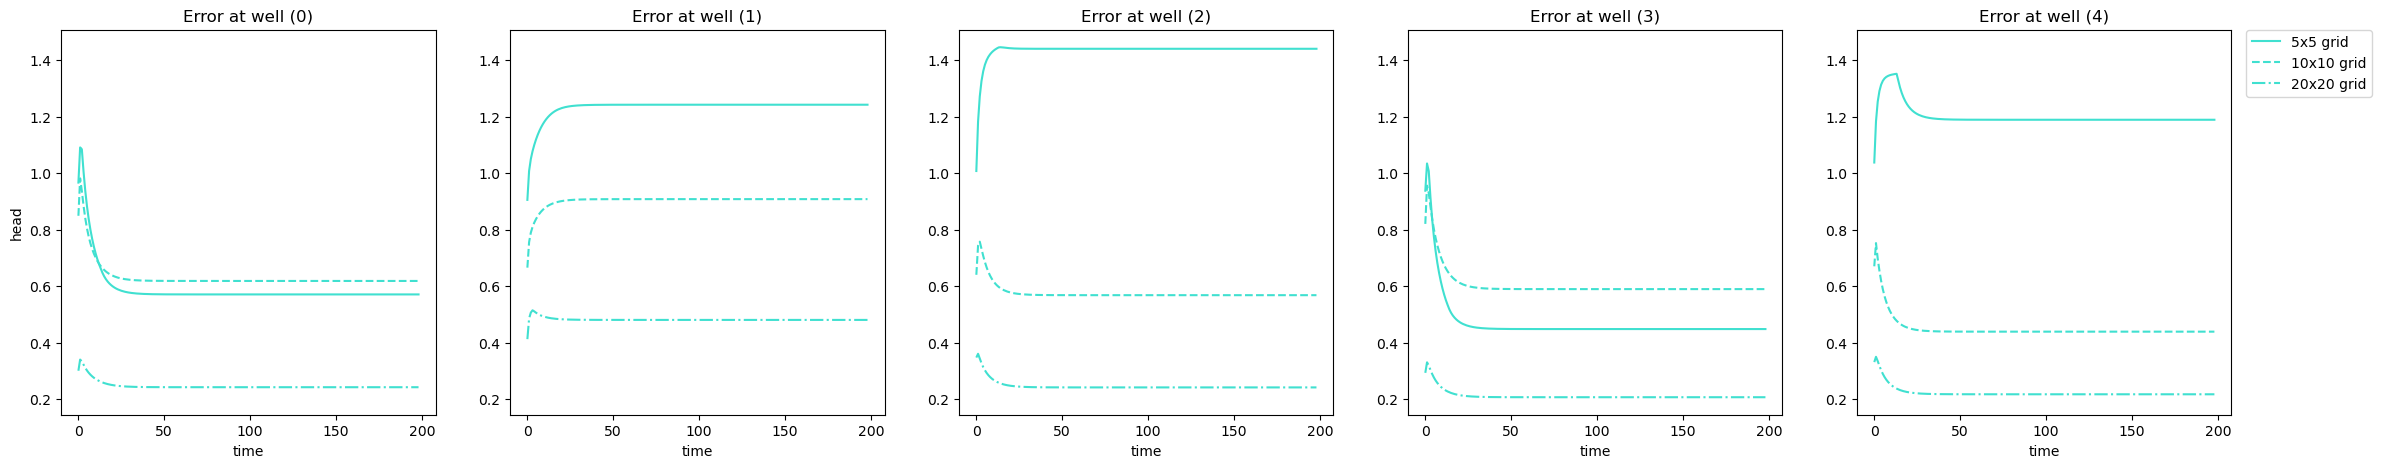

In [ ]:
# Display difference with real in-well heads
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Error at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(-data['h_wells'][ii, 1:] + data['pred_avg_h_wells'][ii, 1, :-1], c="turquoise", label="5x5 grid")
    ax_h.plot(-data_10['h_wells'][ii, 1:] + data_10['pred_avg_h_wells'][ii, 1, :-1], c="turquoise", linestyle='--', label="10x10 grid")
    ax_h.plot(-data_20['h_wells'][ii, 1:] + data_20['pred_avg_h_wells'][ii, 1, :-1], c="turquoise", linestyle='-.', label="20x20 grid")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)